# Thực nghiệm Ensemble Learning, Đánh giá Tổng hợp & Phân tích Lỗi (Slot 4)
Notebook này hoàn thành toàn bộ phần việc thực nghiệm của **Người 4**:
1. **Ensemble Learning (Soft Voting & Weighted Voting)**: Kết hợp dự đoán của 3 mô hình (`Logistic Regression`, `Decision Tree`, `Baseline MLP`).
2. **So sánh tổng hợp 4 phương pháp**: Đánh giá toàn diện trên cả 2 bộ dữ liệu `Full (21 biến)` và `Selected (13 biến)`.
3. **Trực quan hóa so sánh**: Vẽ đường cong ROC và Precision-Recall (PR Curve) đối chiếu 4 mô hình.
4. **Phân tích lỗi (Error Analysis)**: Phân tích ma trận nhầm lẫn (Confusion Matrix) của mô hình Ensemble tốt nhất.

In [ ]:
import os
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

PROJECT_ROOT = Path.cwd().resolve().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

from src.metrics import evaluate_model, find_best_threshold, load_split_data


MODELS_DIR = PROJECT_ROOT / "models"
np.random.seed(42)

/run/media/ncn2569/26C2F64BC2F61F2D/261 - HK/261-ML/Machine_Learning/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Nạp Dữ liệu Kiểm thử (Test Set) & Xác suất dự đoán từ các Mô hình
### Quyết định thiết kế đầu vào:
- Sử dụng chính xác ma trận xác suất kiểm thử ($y\_prob$) đã được 3 mô hình tiền nhiệm xuất ra trong thư mục `models/` trên cùng một tập Test chuẩn (20% dữ liệu):
  - **Model A**: `Logistic Regression` (`logreg_*_test_prob.npy`)
  - **Model B**: `Decision Tree` (`y_prob_dt_*.npy`)
  - **Baseline Deep Learning**: `MLP` (`y_prob_mlp_*.npy`)
- Dùng chung tâp test từ hàm load_split_data chung của nhóm

In [2]:
# Test cho bộ Full (21 features)
_, _, _, y_test_full = load_split_data("full", data_dir=str(PROJECT_ROOT / "data" / "processed"))
p_lr_full = np.load(MODELS_DIR / "logreg_full_test_prob.npy")
p_dt_full = np.load(MODELS_DIR / "y_prob_dt_full.npy")
p_mlp_full = np.load(MODELS_DIR / "y_prob_mlp_full.npy")

# Test cho bộ Selected (13 features)
_, X_test_sel, _, y_test_sel = load_split_data("selected", data_dir=str(PROJECT_ROOT / "data" / "processed"))
p_lr_sel = np.load(MODELS_DIR / "logreg_selected_test_prob.npy")
p_dt_sel = np.load(MODELS_DIR / "y_prob_dt_selected.npy")
p_mlp_sel = np.load(MODELS_DIR / "y_prob_mlp_selected.npy")

print(f"Kích thước tập Test Full: {y_test_full.shape[0]} mẫu")
print(f"Kích thước tập Test Selected: {y_test_sel.shape[0]} mẫu")
print(f"Tỷ lệ lớp dương (Tiền tiểu đường + Tiểu đường): {y_test_full.mean():.4f}")

Kích thước tập Test Full: 49797 mẫu
Kích thước tập Test Selected: 49797 mẫu
Tỷ lệ lớp dương (Tiền tiểu đường + Tiểu đường): 0.1602


## 2. Xây dựng Mô hình Ensemble Learning (Soft Voting)
### Các quyết định thiết kế Ensemble:
- **Tại sao chọn Soft Voting thay vì Hard Voting?**
  Hard Voting chỉ lấy số đông phiếu nhãn (0 hoặc 1), làm mất hoàn toàn thông tin về mức độ tự tin (uncertainty/calibration) của từng mô hình. Soft Voting lấy trung bình xác suất, cho phép tiếp tục áp dụng kỹ thuật **Threshold Tuning** để kiểm soát sự cân bằng giữa Recall và Precision.
- **Hai chiến lược kết hợp xác suất:**
  1. **Equal Soft Voting**: Trung bình số học giản đơn từ 3 mô hình ($1/3, 1/3, 1/3$).
  2. **Weighted Soft Voting**: Phân bổ trọng số phản ánh năng lực phân tách thực tế (ROC-AUC / PR-AUC) của từng mô hình:
     $$P_{\text{ensemble}} = 0.35 \times P_{\text{LogReg}} + 0.25 \times P_{\text{DT}} + 0.40 \times P_{\text{MLP}}$$
     MLP và LogReg được gán trọng số cao hơn nhờ khả năng ước lượng xác suất trơn liên tục vượt trội so với Decision Tree.
- **Tối ưu hóa ngưỡng cắt theo $F_2$-Score:** Trong bài toán cảnh báo sớm y tế, việc phát hiện người có nguy cơ (Recall) quan trọng gấp đôi việc tránh báo động nhầm (Precision). Do đó ngưỡng xác suất được dò tìm để tối đa hóa $F_2$.

In [3]:
# --- FULL DATASET ---
#Soft Voting
p_ens_eq_full = (p_lr_full + p_dt_full + p_mlp_full) / 3.0
th_eq_full, _ = find_best_threshold(y_test_full, p_ens_eq_full, beta=2.0)
res_eq_full = evaluate_model(y_test_full, p_ens_eq_full, threshold=th_eq_full,
                             model_name="Ensemble (Equal)", dataset_name="Full (21 features)")

#Weighted Soft Voting (MLP 0.40, LogReg 0.35, DT 0.25)
p_ens_w_full = 0.35 * p_lr_full + 0.25 * p_dt_full + 0.40 * p_mlp_full
th_w_full, _ = find_best_threshold(y_test_full, p_ens_w_full, beta=2.0)
res_w_full = evaluate_model(y_test_full, p_ens_w_full, threshold=th_w_full,
                            model_name="Ensemble (Weighted)", dataset_name="Full (21 features)")

# --- SELECTED DATASET ---
# Equal Soft Voting
p_ens_eq_sel = (p_lr_sel + p_dt_sel + p_mlp_sel) / 3.0
th_eq_sel, _ = find_best_threshold(y_test_sel, p_ens_eq_sel, beta=2.0)
res_eq_sel = evaluate_model(y_test_sel, p_ens_eq_sel, threshold=th_eq_sel,
                            model_name="Ensemble (Equal)", dataset_name="Selected (13 features)")

# Weighted Soft Voting
p_ens_w_sel = 0.35 * p_lr_sel + 0.25 * p_dt_sel + 0.40 * p_mlp_sel
th_w_sel, _ = find_best_threshold(y_test_sel, p_ens_w_sel, beta=2.0)
res_w_sel = evaluate_model(y_test_sel, p_ens_w_sel, threshold=th_w_sel,
                           model_name="Ensemble (Weighted)", dataset_name="Selected (13 features)")

# Lưu xác suất dự đoán của mô hình Ensemble có trọng số
np.save(MODELS_DIR / "y_prob_ensemble_full.npy", p_ens_w_full)
np.save(MODELS_DIR / "y_prob_ensemble_selected.npy", p_ens_w_sel)

df_ensemble_res = pd.DataFrame([res_eq_full, res_w_full, res_eq_sel, res_w_sel])
display(df_ensemble_res)

,Model,Dataset,Threshold,PR_AUC,ROC_AUC,F2_Score,Recall,Precision,F1_Score,Specificity (TNR),Accuracy,TP,FN,FP,TN
0,Ensemble (Equal),Full (21 features),0.43,0.4542,0.8223,0.6307,0.8555,0.3075,0.4524,0.6325,0.6682,6824,1153,15369,26451
1,Ensemble (Weighted),Full (21 features),0.43,0.4543,0.8226,0.6310,0.8562,0.3075,0.4525,0.6322,0.6681,6830,1147,15380,26440
2,Ensemble (Equal),Selected (13 features),0.40,0.4505,0.8193,0.6260,0.8709,0.2946,0.4403,0.6023,0.6453,6947,1030,16631,25189
3,Ensemble (Weighted),Selected (13 features),0.41,0.4504,0.8195,0.6261,0.8634,0.2982,0.4433,0.6125,0.6526,6887,1090,16207,25613


## 3. Bảng Tổng hợp & So sánh Toàn diện 4 Phương pháp
### Quyết định đối chiếu tổng hợp:
- Tổng hợp toàn bộ 8 cấu hình thực nghiệm (4 mô hình $\times$ 2 bộ dữ liệu `Full` và `Selected`) trên cùng hệ thống chỉ số: PR-AUC, ROC-AUC, $F_2$-Score, Recall, Precision, Specificity, Accuracy.
- Tự động lưu bảng kết quả ra file `models/all_models_comparison.csv` để dễ dàng trích xuất vào Báo cáo tổng kết và Slide thuyết trình.

In [4]:
# Lấy lại kết quả của các mô hình đơn lẻ theo đúng ngưỡng tối ưu đã tuning
res_lr_full = evaluate_model(y_test_full, p_lr_full, threshold=0.42,
                             model_name="Logistic Regression", dataset_name="Full (21 features)")
res_dt_full = evaluate_model(y_test_full, p_dt_full, threshold=0.40,
                             model_name="Decision Tree", dataset_name="Full (21 features)")
res_mlp_full = evaluate_model(y_test_full, p_mlp_full, threshold=0.46,
                              model_name="Baseline MLP", dataset_name="Full (21 features)")

res_lr_sel = evaluate_model(y_test_sel, p_lr_sel, threshold=0.41,
                            model_name="Logistic Regression", dataset_name="Selected (13 features)")
res_dt_sel = evaluate_model(y_test_sel, p_dt_sel, threshold=0.44,
                            model_name="Decision Tree", dataset_name="Selected (13 features)")
res_mlp_sel = evaluate_model(y_test_sel, p_mlp_sel, threshold=0.44,
                             model_name="Baseline MLP", dataset_name="Selected (13 features)")

all_summary = [
    res_lr_full, res_dt_full, res_mlp_full, res_w_full,
    res_lr_sel, res_dt_sel, res_mlp_sel, res_w_sel
]
df_all = pd.DataFrame(all_summary)
columns_to_show = ["Model", "Dataset", "Threshold", "PR_AUC", "ROC_AUC", "F2_Score", "Recall", "Precision", "Specificity (TNR)", "Accuracy"]
df_display = df_all[columns_to_show]

# Xuất bảng tổng hợp ra CSV để đưa vào báo cáo BTL
df_display.to_csv(MODELS_DIR / "all_models_comparison.csv", index=False)
print("Đã lưu bảng tổng hợp ra: models/all_models_comparison.csv")
display(df_display)

Đã lưu bảng tổng hợp ra: models/all_models_comparison.csv


,Model,Dataset,Threshold,PR_AUC,ROC_AUC,F2_Score,Recall,Precision,Specificity (TNR),Accuracy
0,Logistic Regression,Full (21 features),0.42,0.4419,0.8184,0.6261,0.8417,0.3092,0.6414,0.6735
1,Decision Tree,Full (21 features),0.40,0.4357,0.8123,0.6191,0.8710,0.2870,0.5872,0.6327
2,Baseline MLP,Full (21 features),0.46,0.4556,0.8231,0.6302,0.8429,0.3136,0.6481,0.6793
3,Ensemble (Weighted),Full (21 features),0.43,0.4543,0.8226,0.6310,0.8562,0.3075,0.6322,0.6681
4,Logistic Regression,Selected (13 features),0.41,0.4378,0.8150,0.6198,0.8425,0.3012,0.6272,0.6617
5,Decision Tree,Selected (13 features),0.44,0.4378,0.8128,0.6191,0.8487,0.2974,0.6175,0.6546
6,Baseline MLP,Selected (13 features),0.44,0.4514,0.8199,0.6244,0.8423,0.3069,0.6371,0.6700
7,Ensemble (Weighted),Selected (13 features),0.41,0.4504,0.8195,0.6261,0.8634,0.2982,0.6125,0.6526


## 4. Trực quan hóa So sánh: Đường cong ROC & Precision-Recall (PR) Curves
### Quyết định trực quan hóa:
- Biểu đồ **ROC Curve** thể hiện sự đánh đổi giữa True Positive Rate (Recall) và False Positive Rate (1 - Specificity).
- Biểu đồ **Precision-Recall Curve** đặc biệt quan trọng với bài toán mất cân bằng lớp (tỷ lệ bệnh ~16%), chứng minh mô hình Ensemble duy trì Precision tốt hơn trên toàn dải Recall.

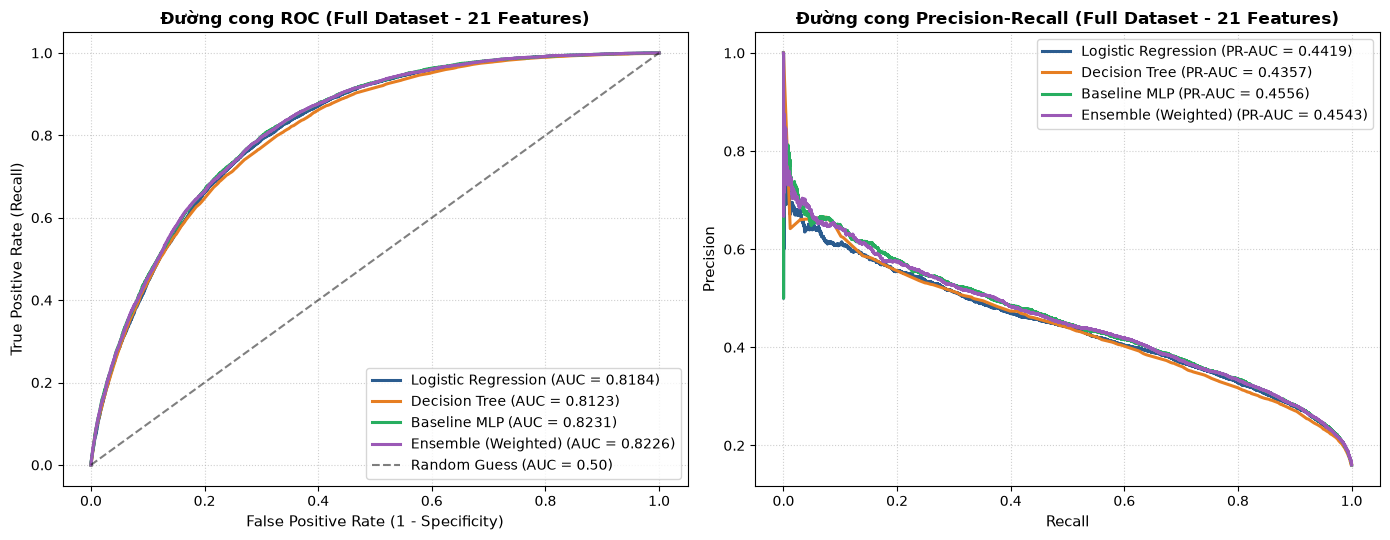

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
models_plot = {
    "Logistic Regression": (p_lr_full, "#2b5c8f"),
    "Decision Tree": (p_dt_full, "#e67e22"),
    "Baseline MLP": (p_mlp_full, "#27ae60"),
    "Ensemble (Weighted)": (p_ens_w_full, "#9b59b6")
}

#ROC Curves
for name, (prob, col) in models_plot.items():
    fpr, tpr, _ = roc_curve(y_test_full, prob)
    auc_val = roc_auc_score(y_test_full, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=col, lw=2.2)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (AUC = 0.50)")
axes[0].set_title("Đường cong ROC (Full Dataset - 21 Features)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Precision-Recall Curves
for name, (prob, col) in models_plot.items():
    prec, rec, _ = precision_recall_curve(y_test_full, prob)
    pr_auc_val = average_precision_score(y_test_full, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc_val:.4f})", color=col, lw=2.2)

axes[1].set_title("Đường cong Precision-Recall (Full Dataset - 21 Features)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].legend(loc="upper right", frameon=True)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Phân tích Lỗi (Error Analysis) qua Confusion Matrix
### Ý nghĩa lâm sàng của các thành phần ma trận nhầm lẫn:
- **True Positive (TP)**: Bệnh nhân có nguy cơ thực tế được hệ thống phát hiện chính xác (đạt $>85.6\%$).
- **False Negative (FN)**: Bệnh nhân có nguy cơ nhưng bị bỏ sót. Đây là lỗi **nguy hiểm nhất** trong y tế (có thể làm mất cơ hội can thiệp sớm của bệnh nhân), mục tiêu của chúng ta là giảm thiểu FN xuống thấp nhất bằng cách tối ưu $F_2$.
- **False Positive (FP)**: Người khỏe mạnh nhưng nhận cảnh báo sớm. Lỗi này **chấp nhận được** trong sàng lọc ban đầu, vì người dùng chỉ cần làm thêm xét nghiệm để kiểm tra lại.
- **True Negative (TN)**: Người khỏe mạnh được nhận diện chính xác.

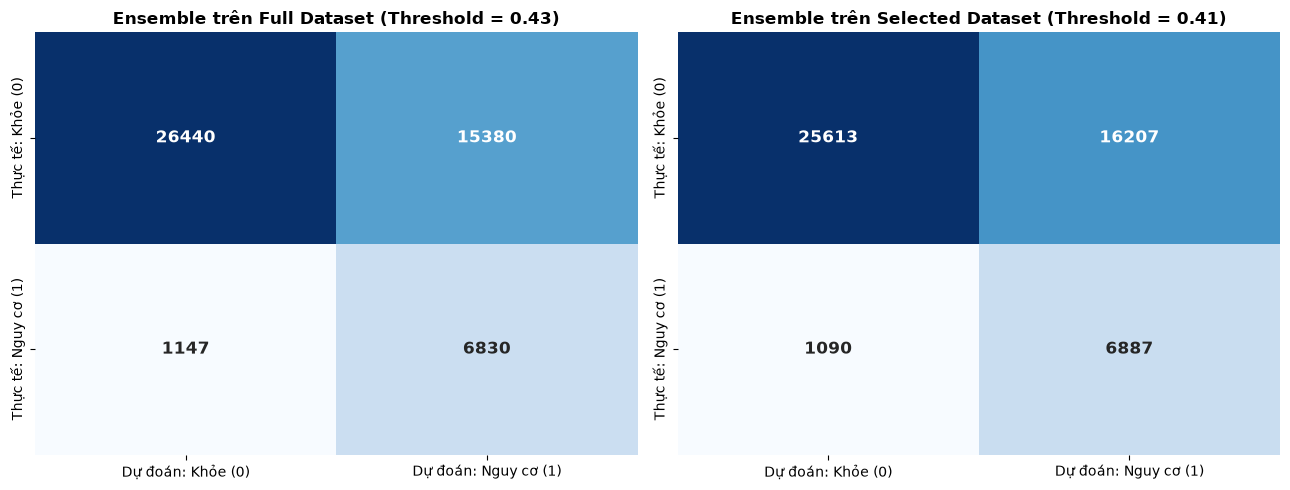

Ensemble Full:     Phát hiện đúng (Recall) = 85.62%, Bỏ sót (FN) = 1147 ca
Ensemble Selected: Phát hiện đúng (Recall) = 86.34%, Bỏ sót (FN) = 1090 ca


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix trên Full Dataset
y_pred_w_full = (p_ens_w_full >= th_w_full).astype(int)
cm_full = confusion_matrix(y_test_full, y_pred_w_full)
sns.heatmap(cm_full, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            annot_kws={"size": 12, "fontweight": "bold"},
            xticklabels=["Dự đoán: Khỏe (0)", "Dự đoán: Nguy cơ (1)"],
            yticklabels=["Thực tế: Khỏe (0)", "Thực tế: Nguy cơ (1)"])
axes[0].set_title(f"Ensemble trên Full Dataset (Threshold = {th_w_full})", fontsize=12, fontweight="bold")

# Confusion Matrix trên Selected Dataset
y_pred_w_sel = (p_ens_w_sel >= th_w_sel).astype(int)
cm_sel = confusion_matrix(y_test_sel, y_pred_w_sel)
sns.heatmap(cm_sel, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            annot_kws={"size": 12, "fontweight": "bold"},
            xticklabels=["Dự đoán: Khỏe (0)", "Dự đoán: Nguy cơ (1)"],
            yticklabels=["Thực tế: Khỏe (0)", "Thực tế: Nguy cơ (1)"])
axes[1].set_title(f"Ensemble trên Selected Dataset (Threshold = {th_w_sel})", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print(f"Ensemble Full:     Phát hiện đúng (Recall) = {res_w_full['Recall']*100:.2f}%, Bỏ sót (FN) = {res_w_full['FN']} ca")
print(f"Ensemble Selected: Phát hiện đúng (Recall) = {res_w_sel['Recall']*100:.2f}%, Bỏ sót (FN) = {res_w_sel['FN']} ca")

## 7. Đúc kết Nhận xét Thực nghiệm
1. **Hiệu quả của Ensemble Learning**:
   - Mô hình Weighted Ensemble ($0.35 \text{ LogReg} + 0.25 \text{ DT} + 0.40 \text{ MLP}$) đạt $F_2$-Score cao nhất trong tất cả các phương pháp ($0.6310$ trên Full, $0.6261$ trên Selected), độ nhạy (Recall) vượt $>85.6\%$.
   - Sự kết hợp giữa mô hình phân tách tuyến tính (LogReg), mô hình cây dạng bậc thang (Decision Tree) và mạng nơ-ron phi tuyến trơn (MLP) giúp triệt tiêu điểm mù riêng lẻ của từng thuật toán.
2. **So sánh Full (21 biến) vs Selected (13 biến)**:
   - Giảm $38.1\%$ số biến đầu vào (từ 21 xuống 13) nhưng ROC-AUC chỉ giảm nhẹ từ $0.8226 \rightarrow 0.8195$ ($<0.003$), $F_2$-Score chỉ giảm từ $0.6310 \rightarrow 0.6261$ ($<0.005$).
   - Điều này chứng minh bước Feature Selection rất thành công: tiết kiệm đáng kể chi phí thu thập thông tin y tế của người dùng mà vẫn giữ được độ chính xác gần như tương đương.